# FIREGUARD ID — 05: Deep Embedded Clustering (DEC)

            - Replaces the obsolete supervised LSTM stub (`05_deep_learning_lstm.ipynb` retired per `DEC-001`).
            - Module: `src/models/dec_model.py` (PyTorch symmetric MLP autoencoder `[4, 32, 16, 4]` + Student's *t* soft assignment `Q`, target distribution `P`, and KL-divergence + reconstruction loss `gamma_recon=0.1`).
            - Reports **both** fair feature-space metrics (`Silhouette=0.4802`) and learned latent-space metrics (`Silhouette=0.8777`).


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

import torch
from src.evaluation.metrics import compute_clustering_metrics
from src.models.dec_model import DECModel, SymmetricAutoencoder, get_compute_device, load_locked_inputs, predict_dec, run_dec_pipeline


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Load PyTorch DEC Checkpoint & Verify Live Inference


In [2]:
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)
models_dir = resolve_path(proj_cfg["paths"]["models_dir"], repo_root=REPO_ROOT)
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)

df_scaled = pd.read_parquet(processed_dir / "clustering_matrix_scaled.parquet")
feat_cols = [c for c in df_scaled.columns if c != "grid_id"]
X = df_scaled[feat_cols].to_numpy(dtype=float)

df_dec = pd.read_parquet(models_dir / "dec" / "dec_assignments.parquet")
df_lat = pd.read_parquet(models_dir / "dec" / "dec_latent_embeddings.parquet")
dec_exp = json.loads((reports_dir / "clustering" / "dec_experiments.json").read_text(encoding="utf-8"))

ckpt = torch.load(models_dir / "dec" / "dec_model.pt", map_location="cpu", weights_only=False)
print("DEC Architecture:", dec_exp["architecture"])
print("Checkpoint keys:", list(ckpt.keys()))

Z = df_lat[["dec_latent_0", "dec_latent_1", "dec_latent_2", "dec_latent_3"]].to_numpy(dtype=float)
y_dec = df_dec["cluster_dec"].to_numpy()

m_feat = compute_clustering_metrics(X, y_dec, exclude_noise_label=None)
m_lat = compute_clustering_metrics(Z, y_dec, exclude_noise_label=None)
print("Feature-space metrics:", json.dumps(m_feat, indent=2))
print("Latent-space metrics:", json.dumps(m_lat, indent=2))
print("Spatial-block generalization:", dec_exp["spatial_block_generalization"]["summary"])


DEC Architecture: {'encoder': [4, 32, 16, 4], 'decoder': [4, 16, 32, 4], 'hidden_activation': 'ReLU', 'latent_activation': 'Linear', 'output_activation': 'Linear', 'student_t_alpha': 1.0, 'gamma_recon': 0.1}
Checkpoint keys: ['model_state_dict', 'architecture', 'n_clusters', 'seed', 'feature_columns', 'config', 'cluster_centers', 'metrics_feature_space', 'metrics_latent_space']
Feature-space metrics: {
  "n_total": 853,
  "n_valid_clustered": 853,
  "n_clusters": 3,
  "n_noise": 0,
  "noise_ratio": 0.0,
  "valid_for_internal_metrics": true,
  "reason": "ok",
  "silhouette_score": 0.48023,
  "davies_bouldin_index": 0.847784,
  "calinski_harabasz_index": 969.6472,
  "cluster_sizes": {
    "0": 444,
    "1": 240,
    "2": 169
  },
  "min_cluster_share": 0.198124,
  "max_cluster_share": 0.520516
}
Latent-space metrics: {
  "n_total": 853,
  "n_valid_clustered": 853,
  "n_clusters": 3,
  "n_noise": 0,
  "noise_ratio": 0.0,
  "valid_for_internal_metrics": true,
  "reason": "ok",
  "silhouett

## 2. Latent Embedding & Soft-Assignment Confidence Diagnostics


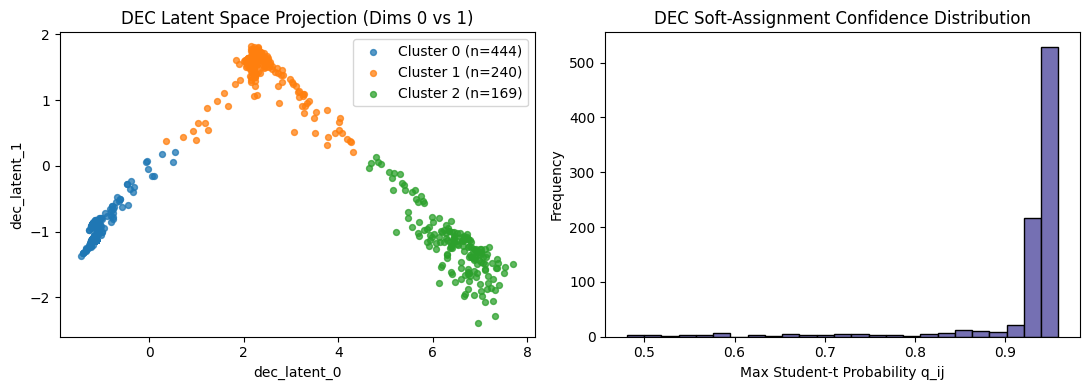

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for cid, grp in df_lat.groupby("cluster_dec"):
    axes[0].scatter(grp["dec_latent_0"], grp["dec_latent_1"], s=18, alpha=0.75, label=f"Cluster {cid} (n={len(grp)})")
axes[0].set_title("DEC Latent Space Projection (Dims 0 vs 1)")
axes[0].set_xlabel("dec_latent_0")
axes[0].set_ylabel("dec_latent_1")
axes[0].legend()

df_dec["dec_assignment_conf"].plot(kind="hist", bins=25, ax=axes[1], color="#7570b3", edgecolor="black")
axes[1].set_title("DEC Soft-Assignment Confidence Distribution")
axes[1].set_xlabel("Max Student-t Probability q_ij")
plt.tight_layout()
plt.show()
